# Atlas-DeePC: Position-Only Tracking Cost

**100 paired seeds (211--310), at each of five noise levels.** Both methods use
$\lambda_g=0$ and the same offline/online Gaussian noise convention as
[the measurement-noise study](ablation_measurement_noise.ipynb).
The new method changes **only the non-position entries of the tracking matrix $Q$**:

$$Q_{\rm full}=\operatorname{diag}(5000,5000,5000,5000,20,20,10^5,10^5,5000,5000),$$
$$Q_{\rm position}=\operatorname{diag}(0,0,0,0,0,0,10^5,10^5,0,0).$$

The ten outputs remain ordered as $[\cos q_1,\cos q_2,\sin q_1,\sin q_2,
\dot q_1,\dot q_2,p_x,p_y,\cos(q_1+q_2),\sin(q_1+q_2)]$.
This is **not an output-dimension ablation** and does not remove configuration
information from the controller.

Unchanged: 48 physical charts; rank-60 linear bases; two past steps; ten future
steps; iterative N=10 full terminal-reference generation; graph waypoint routing;
7 cm reference latch; coefficient bounds; input limits; and all remaining costs.
In particular, past-output slack is penalized on **all ten channels** with
$\lambda_{\rm ini}=10^5$. $R=10^{-4}I$, $\lambda_{\Delta u}=5$, and the additional
terminal cost is zero. There is no filtering, rescue, model fitting, IK, or tuning.

Offline atlases and bases are reused directly, not reclustered. Previous
full-configuration-Q results are reused; only the new position-only-Q runs are
computed. These are exploratory ablation seeds, not a new untouched test set.


In [1]:
import os
os.environ.setdefault("MPLCONFIGDIR", "/tmp/atlas_deepc_mpl")
import sys
import json
from pathlib import Path
from dataclasses import asdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML, display
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "src/position_only_q_ablation.py").exists())
sys.path.insert(0, str(ROOT / "src"))
import position_only_q_ablation as experiment
noise = experiment.noise
get_ipython().run_line_magic("matplotlib", "inline")
SEEDS = list(range(211, 311))
SD_RATIOS = [0., .01, .02, .05, .10]
RUN_EXPERIMENTS = False
WORKERS = 4
RESULT_ROOT = experiment.RESULT_ROOT
if RUN_EXPERIMENTS:
    experiment.run_all(SD_RATIOS, SEEDS, WORKERS)
FULL, POSITION = "Full-configuration Q", "Position-only Q"
COLORS = {FULL: "#0072B2", POSITION: "#D55E00"}
payloads, records, errors = {}, [], {}
for ratio in SD_RATIOS:
    for method, directory in [(FULL, experiment.BASELINE_ROOT), (POSITION, RESULT_ROOT)]:
        folder = directory / noise.level_name(ratio)
        path = folder / "summary.json"
        assert path.exists(), f"Missing {method}, noise SD {ratio}: enable RUN_EXPERIMENTS."
        payload = json.loads(path.read_text())
        assert payload["seeds"] == SEEDS and len(payload["results"]) == 100
        assert {r["seed"] for r in payload["results"]} == set(SEEDS)
        payloads[method, ratio] = payload
        if method == POSITION:
            assert payload["version"] == experiment.VERSION
        for row in payload["results"]:
            assert row["steps"] == 320 and row["lam_g"] == 0
            assert row["evaluation_uses_true_outputs"] and row["noise_sd_ratio"] == ratio
            assert row["clusters"] == 48 and row["svd_rank"] == 60 and row["candidate_count"] == 10
            assert row["q_data_goal_joint"] == (5000 if method == FULL else 0)
            assert row["q_dq"] == (20 if method == FULL else 0)
            if method == POSITION:
                assert row["tracking_Q_diagonal"] == [0]*6 + [100000]*2 + [0]*2
                assert row["nonposition_outputs_retained"] and row["augmented_output_dimension"] == 10
            with np.load(folder / f"seed{row['seed']}_control_results.npz", allow_pickle=True) as trace:
                error = 1000*trace["distance"]
                prediction_error = 1000*np.mean(trace["prediction_error_xy"][-100:])
                joint_speed = np.sqrt(np.mean(np.sum(trace["y"][-100:, 4:6]**2, axis=1)))
                saturated = 100*np.mean(np.any(np.abs(trace["u"]) >= .999, axis=1))
            errors[method, ratio, row["seed"]] = error
            tail = error[-100:]
            records.append({**row, "method": method, "strict_success": row["success_30"] and row["success_100"],
                "tail_rmse_mm": np.sqrt(np.mean(tail**2)), "tail_std_mm": np.std(tail),
                "tail_prediction_error_mm": prediction_error, "tail_joint_speed_rms": joint_speed,
                "saturated_steps_pct": saturated, "ever_below_10": bool(np.min(error) < 10),
                "tail_within_10_pct": 100*np.mean(tail < 10), "tail_within_20_pct": 100*np.mean(tail < 20)})
frame = pd.DataFrame(records)
print("Loaded 500 new position-only-Q runs and 500 saved full-configuration-Q runs.")


Loaded 500 new position-only-Q runs and 500 saved full-configuration-Q runs.


## 1. Noise Convention and Paired Integrity

Noise SD is $\rho$ times each clean offline channel's standard deviation, with
$\rho\in\{0,0.01,0.02,0.05,0.10\}$. Power NSR is $\rho^2$. The same independent
Gaussian draws are applied in both methods, scaled per output channel. Offline
samples are corrupted once before constructing overlapping Hankel windows.
Inputs and the target are exact; simulator truth is used only for evaluation.
Noise acts independently on the ten lifted channels, not on encoder angles
before lifting. Noisy outputs may therefore be kinematically inconsistent.

The controller policies are unchanged, but their online chart and reference
sequences may differ because the resulting state trajectories differ.


In [2]:
from candidate_goal_routing_experiment import file_digest
noise_rows = []
for ratio in SD_RATIOS:
    old = payloads[FULL, ratio]
    new = payloads[POSITION, ratio]
    old_config = dict(old["artifact"]["signature"]["config"])
    new_config = dict(new["signature"]["config"])
    changed = {k for k in old_config if old_config[k] != new_config[k]}
    assert changed == {"q_data_goal_joint", "q_dq"}
    source_folder = experiment.BASELINE_ROOT / noise.level_name(ratio)
    assert new["signature"]["source_manifest_sha256"] == file_digest(source_folder / "artifact_manifest.json")
    assert new["signature"]["source_signature"] == old["artifact"]["signature"]
    for name, digest in new["signature"]["reused_offline_artifacts"].items():
        assert file_digest(source_folder / name) == digest
    for seed in SEEDS:
        name = f"seed{seed}_control_results.npz"
        with np.load(source_folder/name, allow_pickle=True) as first, np.load(RESULT_ROOT/noise.level_name(ratio)/name, allow_pickle=True) as second:
            np.testing.assert_allclose(first["sensor_measured"]-first["sensor_true"],
                second["sensor_measured"]-second["sensor_true"], rtol=0, atol=1e-12)
            np.testing.assert_array_equal(second["y"], second["sensor_true"][-320:])
            np.testing.assert_array_equal(second["y_measured"], second["sensor_measured"][-320:])
            row = json.loads(second["summary"].item())
            np.testing.assert_allclose(second["distance"], np.linalg.norm(second["y"][:, 6:8]-row["exact_target_xy"], axis=1))
            assert row["minimum_selected_goal_source_separation"] >= .06
    sigma = np.array(old["artifact"]["noise_std"])
    noise_rows.append({"Noise SD (%)": 100*ratio, "Power NSR": ratio**2,
                       "Fingertip x noise SD (mm)": 1000*sigma[6], "Fingertip y noise SD (mm)": 1000*sigma[7]})
display(pd.DataFrame(noise_rows).round(4))
print("Verified: only two Q weights differ; identical cached atlases/bases and matched Gaussian draws for all 500 pairs.")


,Noise SD (%),Power NSR,Fingertip x noise SD (mm),Fingertip y noise SD (mm)
0,0.0,0.0000,0.0000,0.0000
1,1.0,0.0001,1.0057,0.9418
2,2.0,0.0004,2.0115,1.8836
3,5.0,0.0025,5.0287,4.7089
4,10.0,0.0100,10.0575,9.4178


Verified: only two Q weights differ; identical cached atlases/bases and matched Gaussian draws for all 500 pairs.


## 2. Tracking Accuracy and Strict Success

Strict success requires true-error means below 10 mm and maxima below 20 mm in
**both final-30 and final-100 windows**. Every rollout retains all 320 steps;
failed QPs and unsuccessful rollouts are not excluded. Continuous error metrics
and time within the target neighborhood complement this binary criterion.


Successes /100  Median mean error (mm)  \
Noise SD (%) Method                                                         
0.0          Full-configuration Q              93                   2.062   
             Position-only Q                    0                  87.068   
1.0          Full-configuration Q              90                   2.940   
             Position-only Q                    0                  70.559   
2.0          Full-configuration Q              86                   4.506   
             Position-only Q                    0                  75.699   
5.0          Full-configuration Q              33                  10.849   
             Position-only Q                    0                  70.221   
10.0         Full-configuration Q               2                  17.307   
             Position-only Q                    0                  73.829   

                                   P90 mean error (mm)  \
Noise SD (%) Method                                      
0.0          Full-configuration Q                5.415   
             Position-only Q                   120.928   
1.0          Full-configuration Q                7.440   
             Position-only Q                   100.036   
2.0          Full-configuration Q               10.153   
             Position-only Q                    99.666   
5.0          Full-configuration Q               21.602   
             Position-only Q                    93.409   
10.0         Full-configuration Q               30.672   
             Position-only Q                   108.556   

                                   Mean time below 10 mm (%)  Unsolved QPs  
Noise SD (%) Method                                                         
0.0          Full-configuration Q                      93.00             0  
             Position-only Q                            0.61             0  
1.0          Full-configuration Q                      91.38             0  
             Position-only Q                            2.47             0  
2.0          Full-configuration Q                      87.78             0  
             Position-only Q                            2.07             0  
5.0          Full-configuration Q                      45.57             0  
             Position-only Q                            2.56             0  
10.0         Full-configuration Q                      22.72             0  
             Position-only Q                            2.44             0

Noise SD (%),Method,Successes /100,Median mean error (mm),P90 mean error (mm),Median tail RMSE (mm),Mean time below 10 mm (%),Mean time below 20 mm (%),Median temporal error SD (mm),Ever reached below 10 mm /100,Median tail prediction error (mm),Median tail joint-speed RMS (rad/s),Mean saturated-input steps (%),Unsolved QPs
0.0,Full-configuration Q,93,2.062,5.415,2.071,93.00,98.00,0.000,94,0.679,0.000,3.288,0
0.0,Position-only Q,0,87.068,120.928,90.157,0.61,3.46,13.618,58,33.852,6.132,35.706,0
1.0,Full-configuration Q,90,2.940,7.440,3.008,91.38,96.54,0.797,99,1.808,0.540,4.362,0
1.0,Position-only Q,0,70.559,100.036,81.052,2.47,8.33,35.316,94,26.979,10.916,58.588,0
2.0,Full-configuration Q,86,4.506,10.153,4.841,87.78,94.14,1.181,97,2.651,0.508,6.894,0
2.0,Position-only Q,0,75.699,99.666,84.605,2.07,7.83,35.396,92,27.584,10.944,61.181,0
5.0,Full-configuration Q,33,10.849,21.602,11.277,45.57,84.27,2.819,89,5.622,1.359,12.153,0
5.0,Position-only Q,0,70.221,93.409,79.393,2.56,10.37,37.651,99,26.308,10.685,68.922,0
10.0,Full-configuration Q,2,17.307,30.672,18.298,22.72,61.83,6.782,89,10.608,2.629,35.588,0
10.0,Position-only Q,0,73.829,108.556,85.758,2.44,9.09,39.070,95,30.362,11.931,72.353,0


Ever reached below 10 mm /100  \
Noise SD (%) Method                                                
0.0          Full-configuration Q                             94   
             Position-only Q                                  58   
1.0          Full-configuration Q                             99   
             Position-only Q                                  94   
2.0          Full-configuration Q                             97   
             Position-only Q                                  92   
5.0          Full-configuration Q                             89   
             Position-only Q                                  99   
10.0         Full-configuration Q                             89   
             Position-only Q                                  95   

                                   Median tail joint-speed RMS (rad/s)  \
Noise SD (%) Method                                                      
0.0          Full-configuration Q                                0.000   
             Position-only Q                                     6.132   
1.0          Full-configuration Q                                0.540   
             Position-only Q                                    10.916   
2.0          Full-configuration Q                                0.508   
             Position-only Q                                    10.944   
5.0          Full-configuration Q                                1.359   
             Position-only Q                                    10.685   
10.0         Full-configuration Q                                2.629   
             Position-only Q                                    11.931   

                                   Median tail prediction error (mm)  \
Noise SD (%) Method                                                    
0.0          Full-configuration Q                              0.679   
             Position-only Q                                  33.852   
1.0          Full-configuration Q                              1.808   
             Position-only Q                                  26.979   
2.0          Full-configuration Q                              2.651   
             Position-only Q                                  27.584   
5.0          Full-configuration Q                              5.622   
             Position-only Q                                  26.308   
10.0         Full-configuration Q                             10.608   
             Position-only Q                                  30.362   

                                   Mean saturated-input steps (%)  
Noise SD (%) Method                                                
0.0          Full-configuration Q                           3.288  
             Position-only Q                               35.706  
1.0          Full-configuration Q                           4.362  
             Position-only Q                               58.588  
2.0          Full-configuration Q                           6.894  
             Position-only Q                               61.181  
5.0          Full-configuration Q                          12.153  
             Position-only Q                               68.922  
10.0         Full-configuration Q                          35.588  
             Position-only Q                               72.353

,Repaired,Regressed,Median paired error change (mm)
Noise SD (%),,,
0.0,0,93,84.088
1.0,0,90,66.779
2.0,0,86,70.091
5.0,0,33,56.839
10.0,0,2,57.035


,Repaired,Regressed,Median paired error change (mm),Repaired seeds,Regressed seeds
Noise SD (%),,,,,
0.0,0,93,84.088006,[],"[211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223, 224, 225, 226, 227, 228, 229, 230, 231, 233, 234, 235, 236, 237, 238, 239, 240, 241, 242, 243, 244, 246, 248, 249, 250, 251, 253, 254, 255, 256, 257, 258, 259, 260, 261, 262, 263, 264, 265, 266, 267, 268, 269, 270, 271, 272, 273, 274, 275, 276, 277, 278, 279, 280, 281, 282, 283, 284, 285, 286, 287, 289, 290, 291, 292, 293, 294, 295, 297, 298, 300, 301, 302, 303, 304, 305, 306, 307, 308, 309, 310]"
1.0,0,90,66.778534,[],"[211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223, 224, 225, 226, 227, 228, 229, 230, 231, 232, 233, 235, 237, 238, 239, 240, 241, 242, 243, 244, 246, 247, 248, 249, 250, 253, 254, 256, 257, 258, 259, 260, 261, 262, 263, 264, 265, 266, 267, 268, 269, 270, 271, 272, 273, 275, 276, 277, 278, 279, 280, 282, 284, 285, 286, 287, 288, 289, 290, 291, 292, 293, 294, 295, 296, 297, 298, 300, 301, 302, 303, 304, 305, 306, 307, 308, 309, 310]"
2.0,0,86,70.090973,[],"[211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 223, 224, 225, 226, 227, 228, 229, 230, 232, 233, 234, 235, 237, 238, 239, 240, 241, 242, 243, 244, 246, 247, 248, 249, 250, 251, 253, 254, 255, 256, 257, 258, 259, 260, 261, 262, 263, 265, 266, 267, 268, 269, 270, 271, 272, 273, 274, 275, 276, 278, 279, 281, 283, 285, 286, 287, 288, 289, 290, 291, 292, 294, 295, 297, 300, 301, 302, 303, 304, 305, 306, 307, 308, 309, 310]"
5.0,0,33,56.838869,[],"[215, 217, 218, 220, 221, 223, 224, 226, 227, 233, 235, 238, 240, 241, 243, 244, 250, 253, 259, 266, 268, 269, 271, 273, 278, 282, 288, 291, 295, 301, 304, 305, 306]"
10.0,0,2,57.035375,[],"[224, 241]"


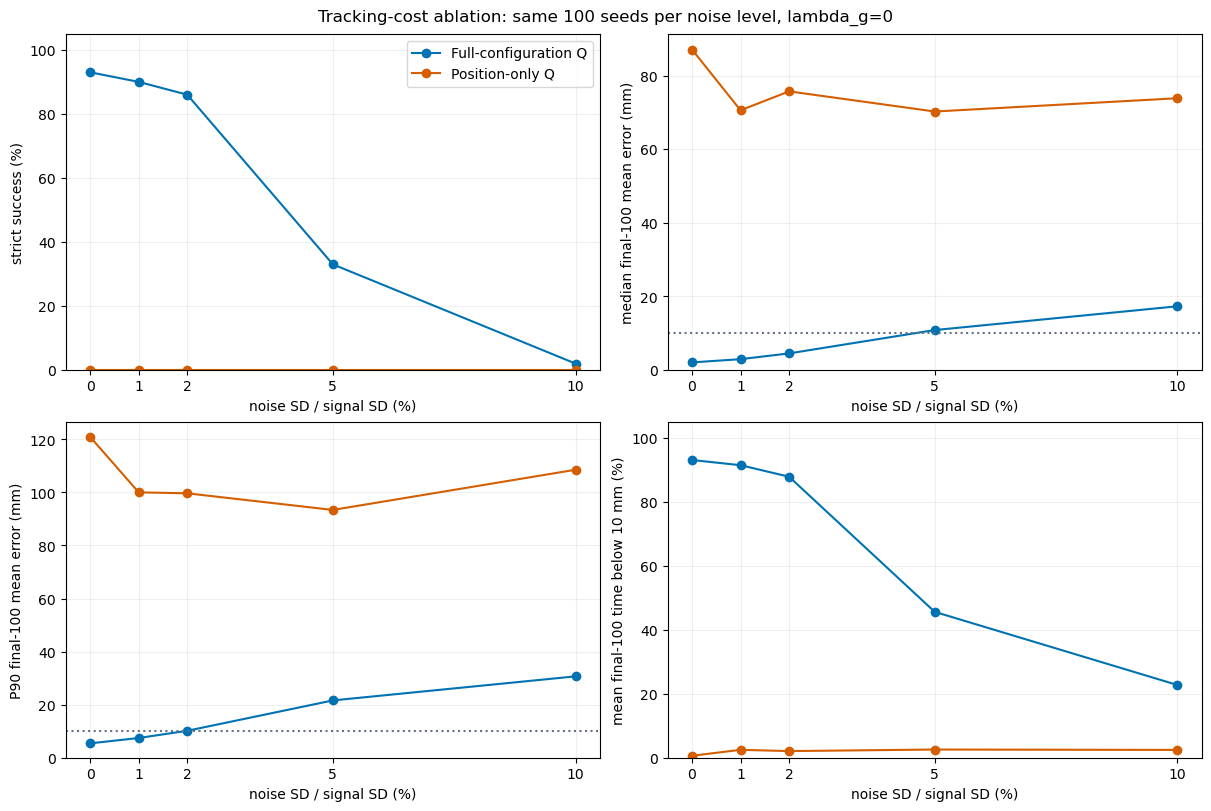

In [3]:
summary_rows, paired_rows = [], []
for ratio in SD_RATIOS:
    for method in (FULL, POSITION):
        rows = frame[(frame.method == method) & (frame.noise_sd_ratio == ratio)]
        summary_rows.append({"Noise SD (%)": 100*ratio, "Method": method,
            "Successes /100": int(rows.strict_success.sum()),
            "Median mean error (mm)": 1000*rows.mean_last_100.median(),
            "P90 mean error (mm)": 1000*rows.mean_last_100.quantile(.9),
            "Median tail RMSE (mm)": rows.tail_rmse_mm.median(),
            "Mean time below 10 mm (%)": rows.tail_within_10_pct.mean(),
            "Mean time below 20 mm (%)": rows.tail_within_20_pct.mean(),
            "Median temporal error SD (mm)": rows.tail_std_mm.median(),
            "Ever reached below 10 mm /100": int(rows.ever_below_10.sum()),
            "Median tail prediction error (mm)": rows.tail_prediction_error_mm.median(),
            "Median tail joint-speed RMS (rad/s)": rows.tail_joint_speed_rms.median(),
            "Mean saturated-input steps (%)": rows.saturated_steps_pct.mean(),
            "Unsolved QPs": int(rows.unsolved_steps.sum())})
    a = frame[(frame.method == FULL) & (frame.noise_sd_ratio == ratio)].set_index("seed").loc[SEEDS]
    b = frame[(frame.method == POSITION) & (frame.noise_sd_ratio == ratio)].set_index("seed").loc[SEEDS]
    repaired = b.index[b.strict_success & ~a.strict_success].tolist()
    regressed = b.index[~b.strict_success & a.strict_success].tolist()
    paired_rows.append({"Noise SD (%)": 100*ratio, "Repaired": len(repaired), "Regressed": len(regressed),
        "Median paired error change (mm)": 1000*(b.mean_last_100-a.mean_last_100).median(),
        "Repaired seeds": repaired, "Regressed seeds": regressed})
summary = pd.DataFrame(summary_rows)
display(summary.set_index(["Noise SD (%)", "Method"])[["Successes /100", "Median mean error (mm)",
        "P90 mean error (mm)", "Mean time below 10 mm (%)", "Unsolved QPs"]].round(3))
display(HTML("<details><summary>All error statistics</summary>" + summary.round(3).to_html(index=False) + "</details>"))
display(HTML("<h3>Reaching versus stabilizing</h3><p>These diagnostics distinguish touching the target from remaining near it. "
             "Prediction error and motion can expose poor closed-loop behavior, but do not by themselves identify its cause.</p>"))
display(summary.set_index(["Noise SD (%)", "Method"])[["Ever reached below 10 mm /100",
    "Median tail joint-speed RMS (rad/s)", "Median tail prediction error (mm)",
    "Mean saturated-input steps (%)"]].round(3))
paired = pd.DataFrame(paired_rows).set_index("Noise SD (%)")
display(paired[["Repaired", "Regressed", "Median paired error change (mm)"]].round(3))
display(HTML("<details><summary>Paired seed lists</summary>" + paired.to_html() + "</details>"))
(RESULT_ROOT / "comparison_report.json").write_text(summary.to_json(orient="records", indent=2))
(RESULT_ROOT / "paired_report.json").write_text(paired.reset_index().to_json(orient="records", indent=2))
fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
for ax, metric, ylabel in zip(axes.flat,
    ["Successes /100", "Median mean error (mm)", "P90 mean error (mm)", "Mean time below 10 mm (%)"],
    ["strict success (%)", "median final-100 mean error (mm)", "P90 final-100 mean error (mm)", "mean final-100 time below 10 mm (%)"]):
    for method in (FULL, POSITION):
        rows = summary[summary.Method == method]
        ax.plot(rows["Noise SD (%)"], rows[metric], "o-", color=COLORS[method], label=method)
    ax.set(ylim=(0, 105) if "%" in ylabel else (0, None), xlabel="noise SD / signal SD (%)", ylabel=ylabel)
    ax.set_xticks(100*np.array(SD_RATIOS))
    if "error (mm)" in ylabel:
        ax.axhline(10, color="#667085", linestyle=":")
    ax.grid(alpha=.2)
axes[0, 0].legend()
fig.suptitle("Tracking-cost ablation: same 100 seeds per noise level, lambda_g=0")
fig.savefig(RESULT_ROOT / "position_only_q_comparison.png", dpi=170)
plt.show()


## 3. Error Distributions Near 10 mm

Each curve is an empirical distribution over 100 **per-seed final-100 mean
errors**. The vertical line is the 10 mm mean-error criterion, not the complete
strict-success test. The zoom does not renormalize the curves: mass beyond the
right boundary remains outside the displayed range. Full-range views follow.


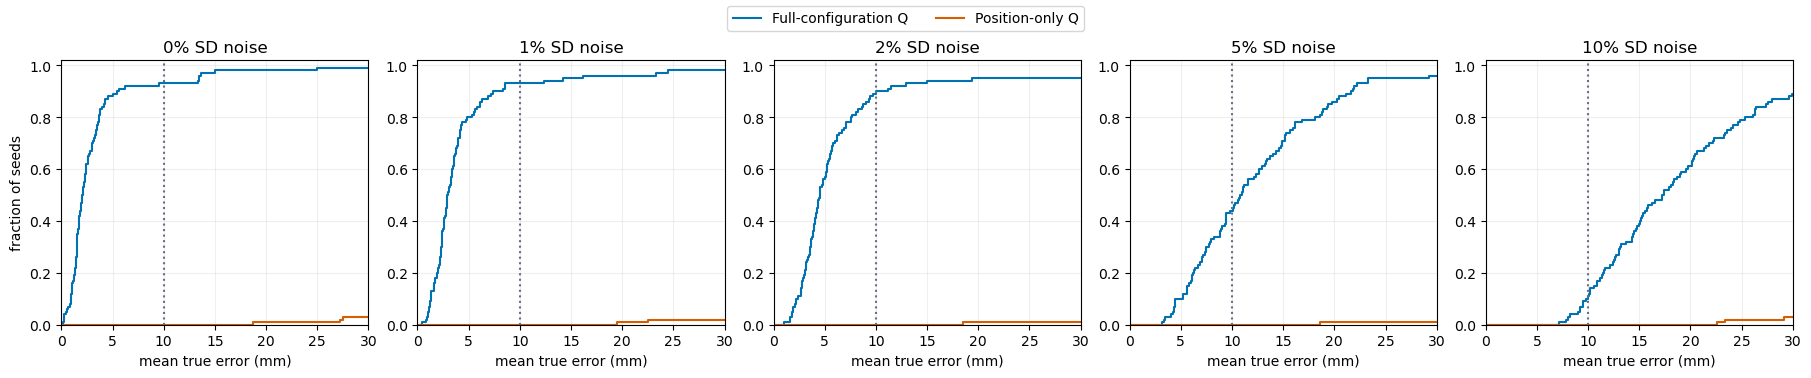

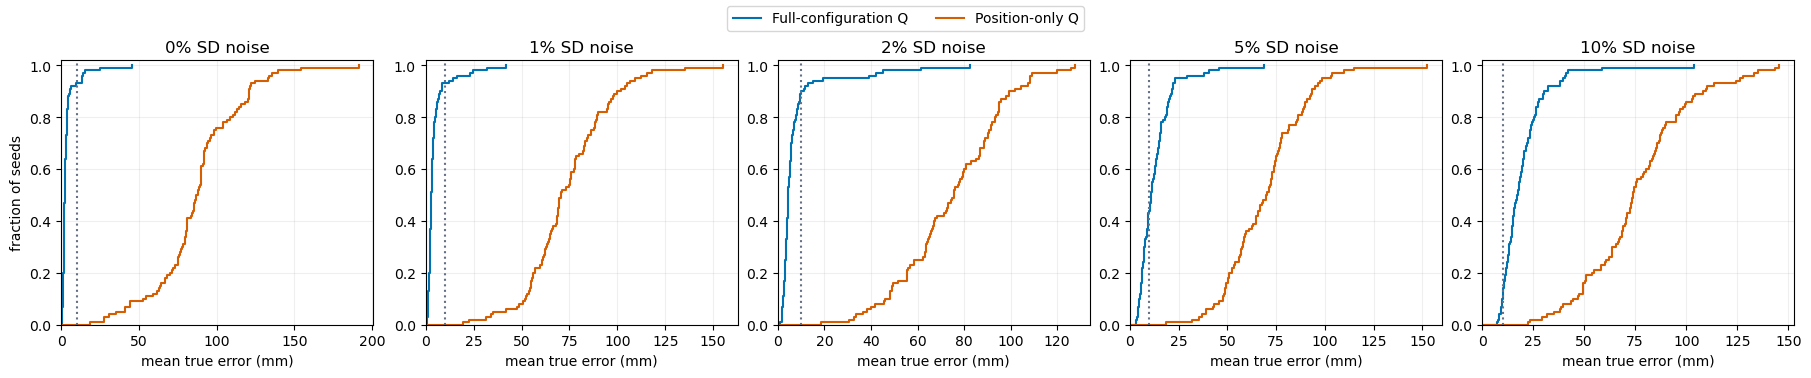

In [4]:
for zoom in (True, False):
    fig, axes = plt.subplots(1, 5, figsize=(18, 3.7), constrained_layout=True)
    for ax, ratio in zip(axes, SD_RATIOS):
        for method in (FULL, POSITION):
            values = np.sort(1000*frame.loc[(frame.method == method) & (frame.noise_sd_ratio == ratio), "mean_last_100"])
            ax.step(np.r_[0, values], np.r_[0, np.arange(1, 101)/100], where="post", color=COLORS[method], label=method)
        ax.axvline(10, color="#667085", linestyle=":")
        ax.set(xlim=(0, 30) if zoom else (0, None), ylim=(0, 1.02), title=f"{100*ratio:g}% SD noise",
               xlabel="mean true error (mm)")
        ax.grid(alpha=.2)
    axes[0].set_ylabel("fraction of seeds")
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="outside upper center", ncol=2)
    suffix = "zoom" if zoom else "full"
    fig.savefig(RESULT_ROOT / f"position_only_q_error_cdf_{suffix}.png", dpi=160)
    plt.show()


## 4. Paired Example Trajectories

Six fixed seeds compare the two costs at every noise level. Each level has a
0--30 mm zoom and a full-range plot. The dashed line marks 10 mm. Triangles at
the top of the zoom mark off-scale samples, not replacement values. Gray shading
marks the final 100 steps. There is no smoothing or early termination.


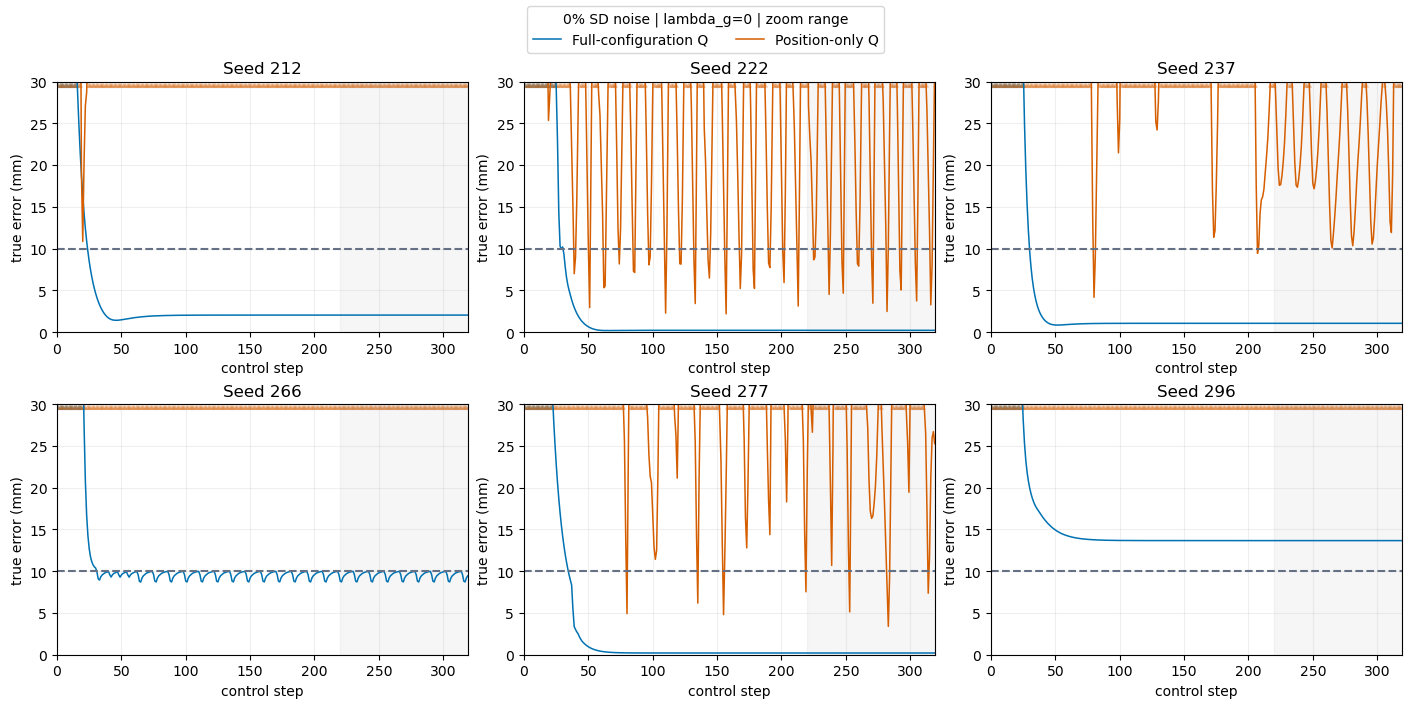

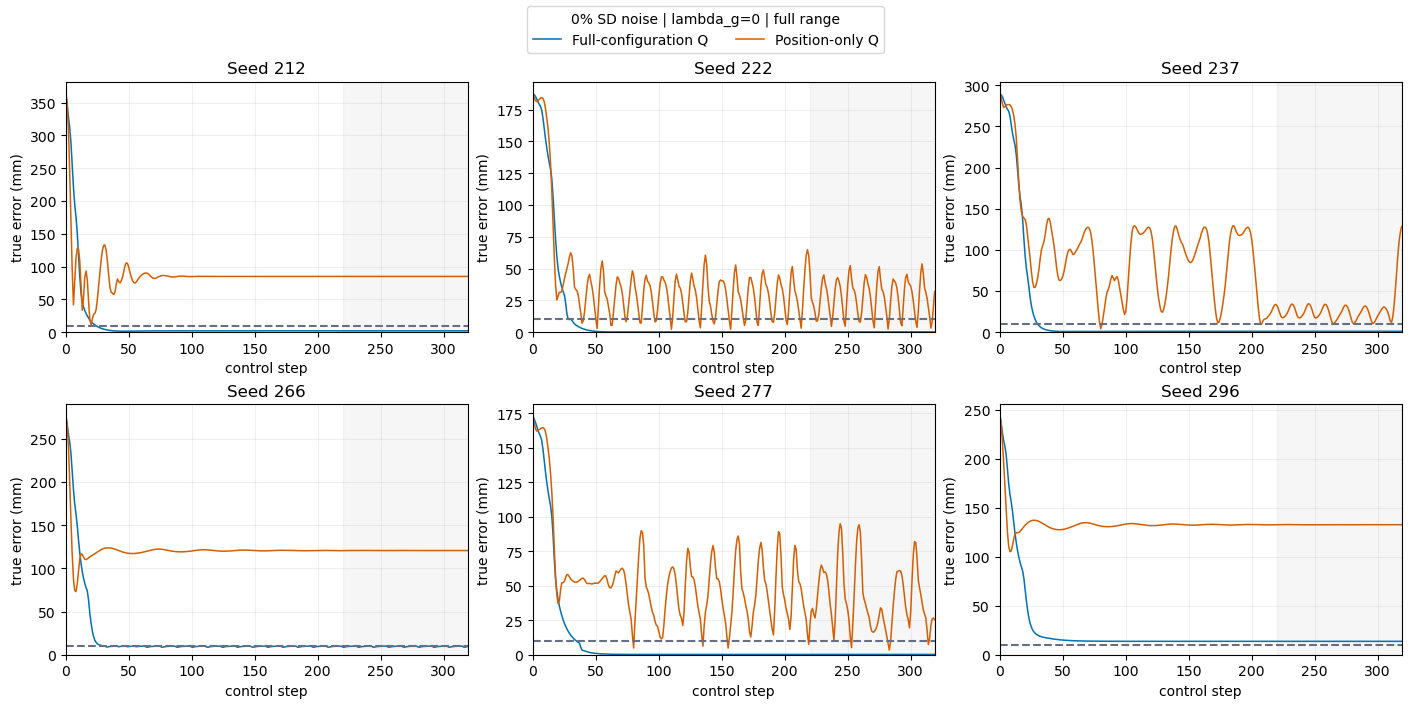

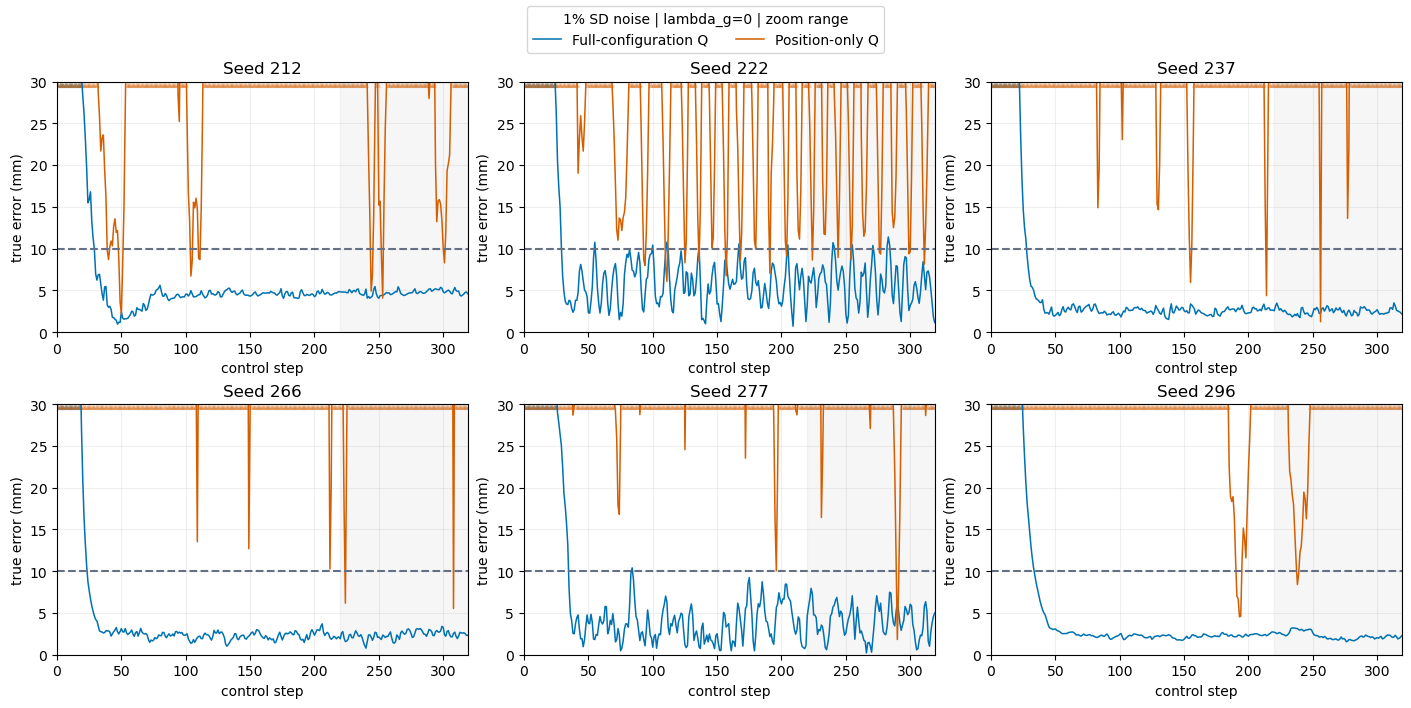

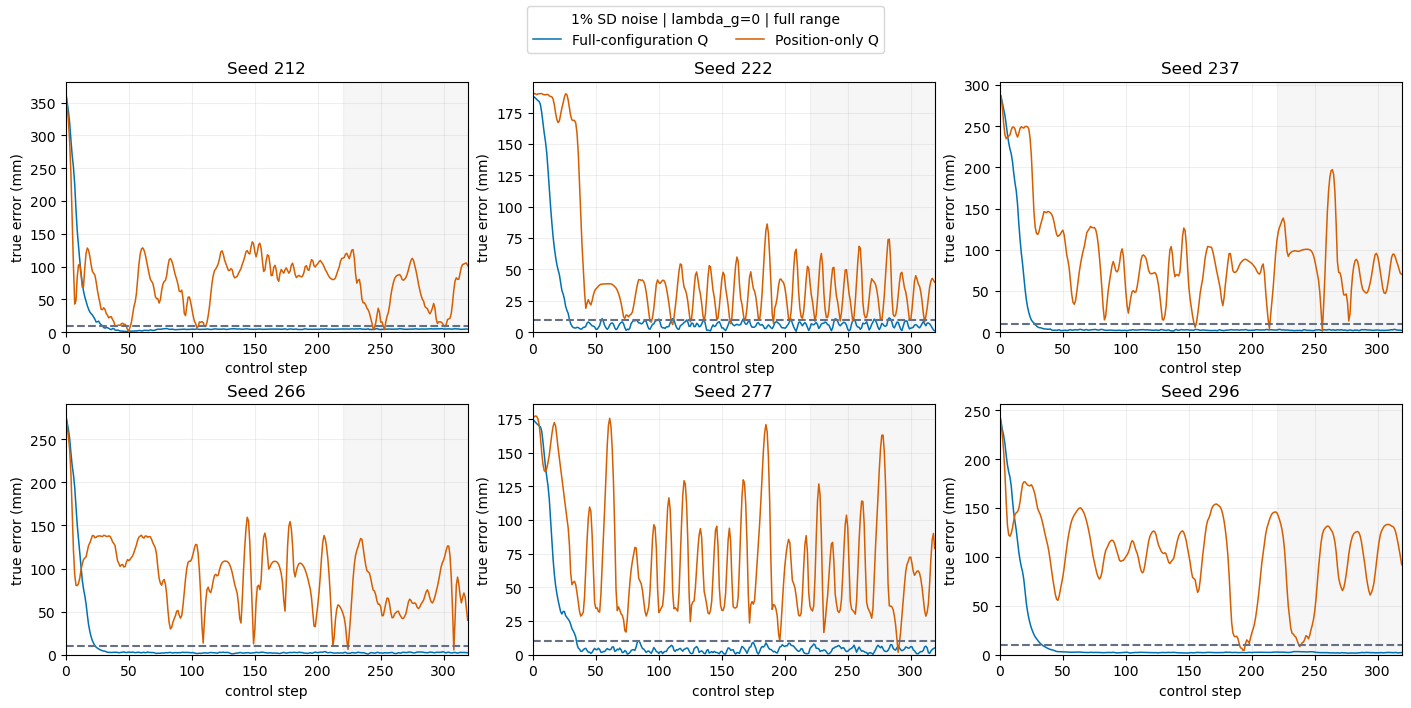

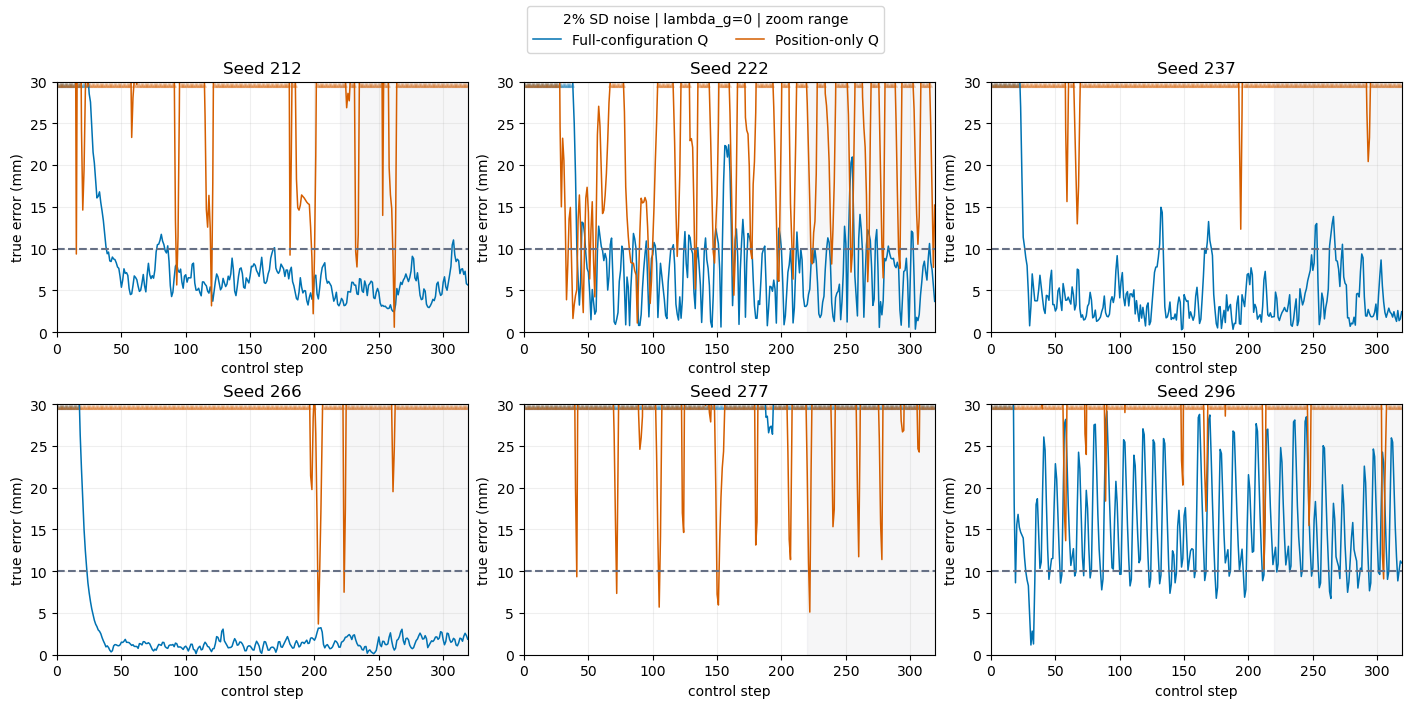

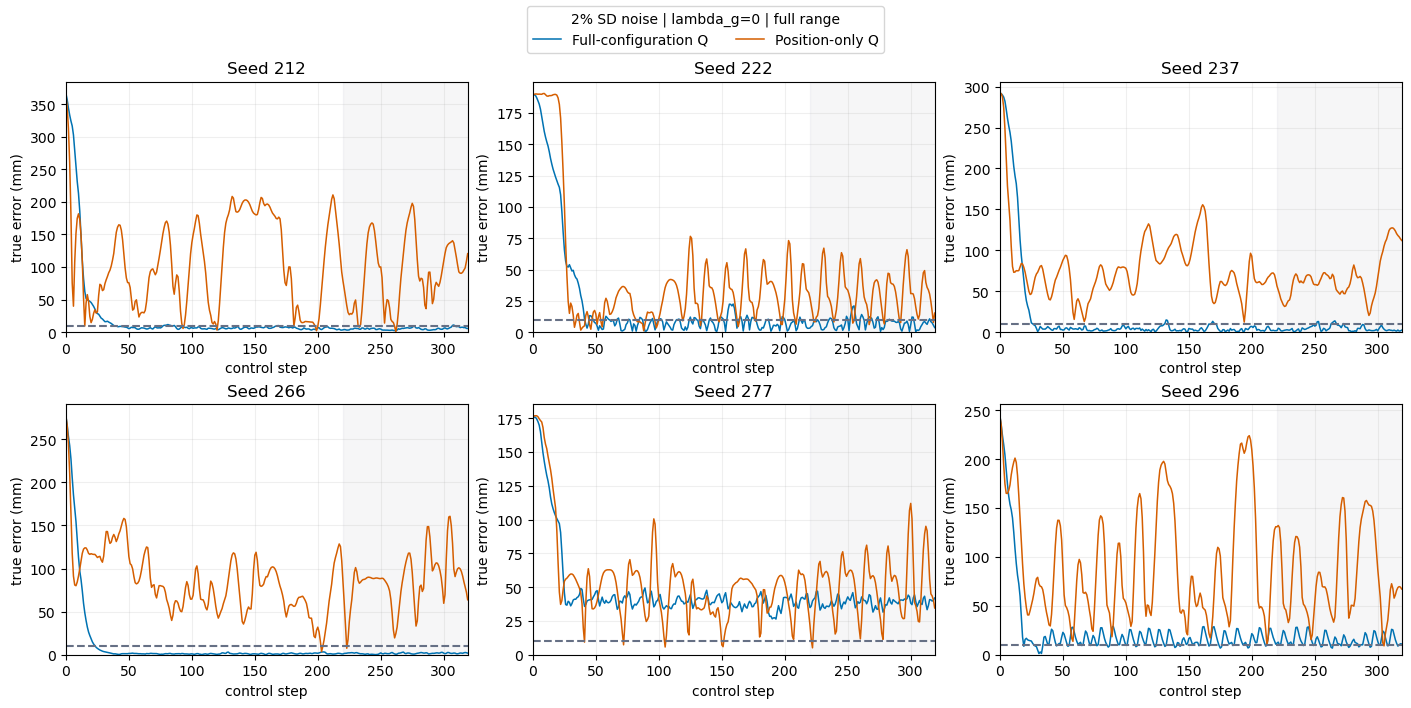

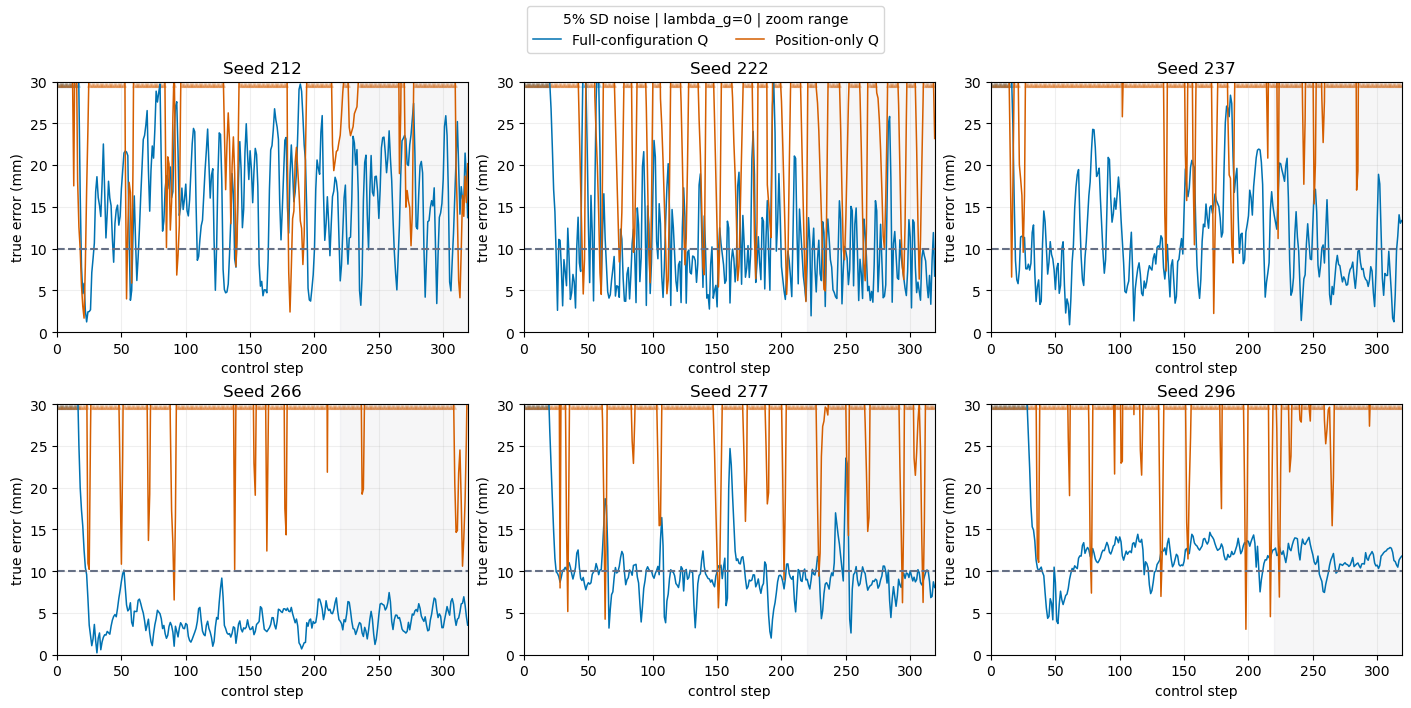

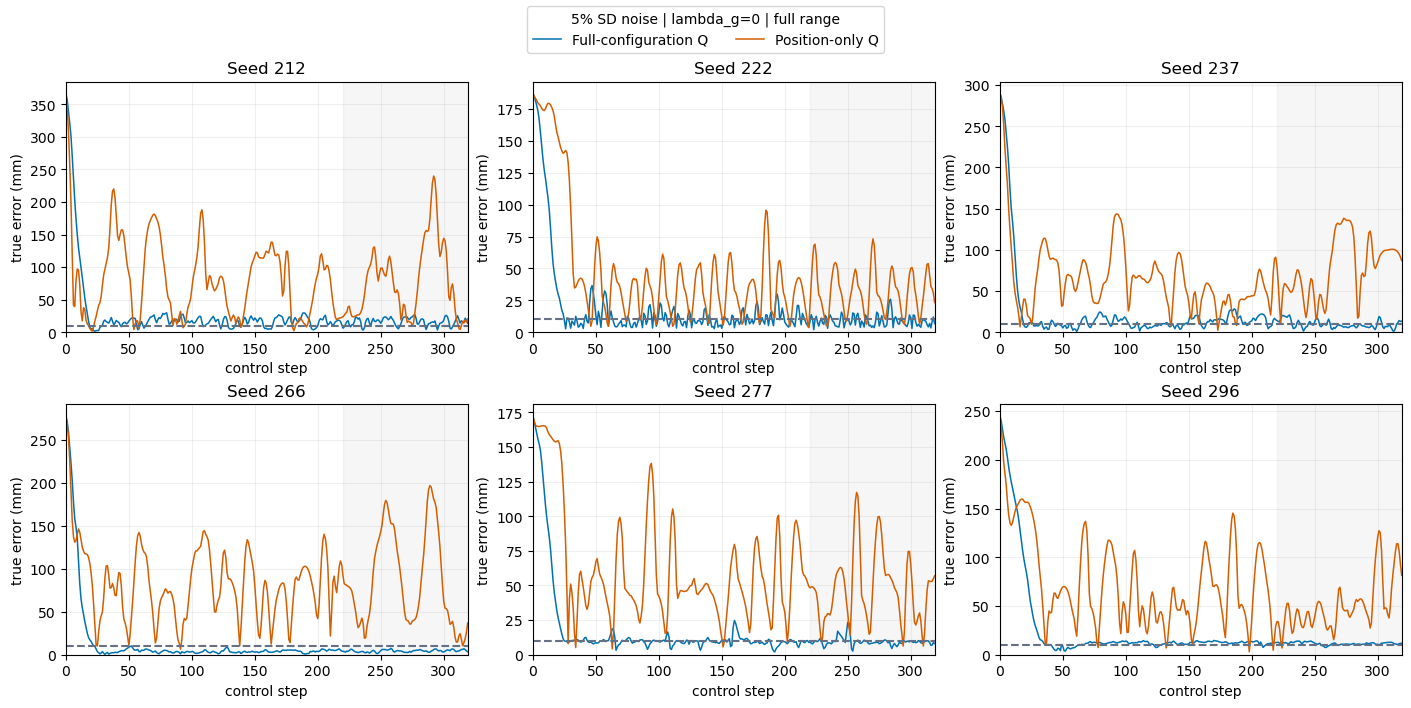

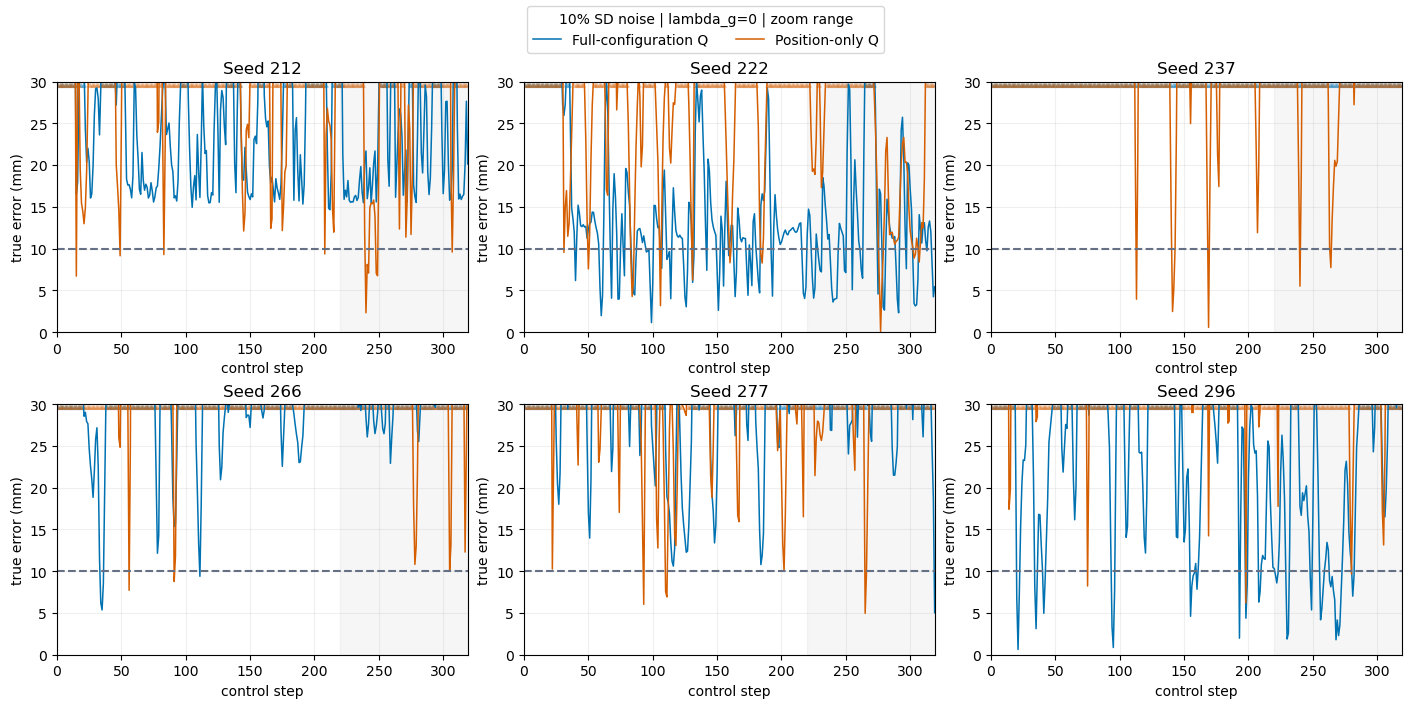

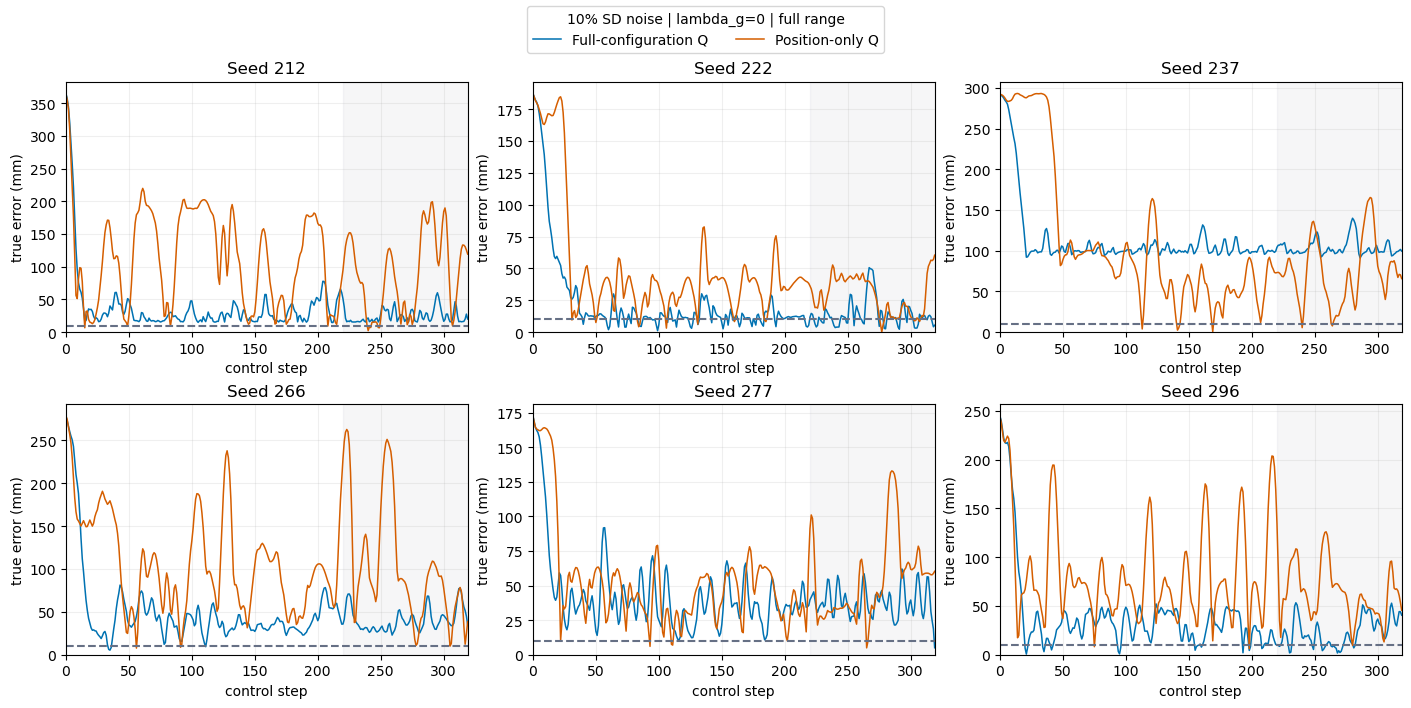

In [5]:
EXAMPLE_SEEDS = [212, 222, 237, 266, 277, 296]
for ratio in SD_RATIOS:
    for zoom in (True, False):
        fig, axes = plt.subplots(2, 3, figsize=(14, 7), constrained_layout=True)
        for ax, seed in zip(axes.flat, EXAMPLE_SEEDS):
            for method in (FULL, POSITION):
                error = errors[method, ratio, seed]
                ax.plot(error, color=COLORS[method], linewidth=1.1, label=method)
                if zoom:
                    outside = np.flatnonzero(error > 30)
                    ax.scatter(outside, np.full(len(outside), 29.6), color=COLORS[method], marker="^", s=7, alpha=.2)
            ax.axvspan(220, 319, color="#667085", alpha=.06)
            ax.axhline(10, color="#667085", linestyle="--")
            ax.set(xlim=(0, 319), ylim=(0, 30) if zoom else (0, None), title=f"Seed {seed}",
                   xlabel="control step", ylabel="true error (mm)")
            ax.grid(alpha=.2)
        handles, labels = axes.flat[0].get_legend_handles_labels()
        suffix = "zoom" if zoom else "full"
        fig.legend(handles, labels, loc="outside upper center", ncol=2,
                   title=f"{100*ratio:g}% SD noise | lambda_g=0 | {suffix} range")
        fig.savefig(RESULT_ROOT / f"position_only_q_traces_{noise.level_name(ratio)}_{suffix}.png", dpi=150)
        plt.show()
selected = frame[frame.seed.isin(EXAMPLE_SEEDS)].copy()
selected["Tail mean (mm)"] = 1000*selected.mean_last_100
selected["Noise SD (%)"] = 100*selected.noise_sd_ratio
display(HTML("<details><summary>Full-range tail errors for example seeds</summary>" +
    selected.pivot(index=["seed", "Noise SD (%)"], columns="method", values="Tail mean (mm)").round(3).to_html() + "</details>"))


## 5. Computation Time

Both panels used four rollout workers with one numerical-library thread per
worker. Times exclude the first five steps, sensor-noise injection, and simulator
stepping; QP time includes construction and solve. The earlier timings are reused
from the previous run. These shared-computer measurements are not an isolated
hardware speed comparison. There is no new offline clustering/SVD cost.


mean_ms  median_ms   p99_ms
Noise SD (%) Method                                           
0.0          Full-configuration Q   37.055     34.704   76.646
             Position-only Q        44.733     41.779   90.112
1.0          Full-configuration Q   35.577     33.820   66.080
             Position-only Q        45.053     42.225   89.673
2.0          Full-configuration Q   50.798     35.995  213.267
             Position-only Q        44.711     41.800   90.109
5.0          Full-configuration Q  113.936    112.004  402.755
             Position-only Q        44.336     41.295   89.359
10.0         Full-configuration Q   50.604     38.977  181.292
             Position-only Q        45.029     41.866   93.926

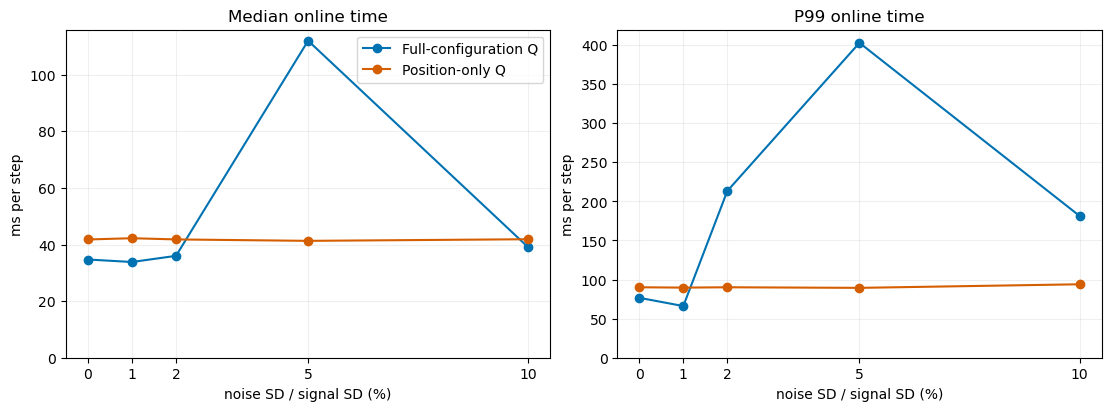

In [6]:
timing = pd.DataFrame([{"Method": method, "Noise SD (%)": 100*ratio, **entry}
    for (method, ratio), payload in payloads.items() for entry in payload["timing"]["modules"]])
assert all(p["timing"]["timed_steps"] == 31500 for p in payloads.values())
total = timing[timing.module == "Total online control"]
display(total.set_index(["Noise SD (%)", "Method"])[["mean_ms", "median_ms", "p99_ms"]].round(3))
display(HTML("<details><summary>All computation modules</summary>" +
    timing.set_index(["Noise SD (%)", "Method", "module"])[["mean_ms", "median_ms", "p99_ms"]].round(4).to_html() + "</details>"))
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for ax, metric, title in zip(axes, ["median_ms", "p99_ms"], ["Median online time", "P99 online time"]):
    for method in (FULL, POSITION):
        rows = total[total.Method == method]
        ax.plot(rows["Noise SD (%)"], rows[metric], "o-", color=COLORS[method], label=method)
    ax.set(ylim=(0, None), xlabel="noise SD / signal SD (%)", ylabel="ms per step", title=title)
    ax.set_xticks(100*np.array(SD_RATIOS))
    ax.grid(alpha=.2)
axes[0].legend()
fig.savefig(RESULT_ROOT / "position_only_q_timing.png", dpi=160)
plt.show()


## Reproduction and Interpretation

```bash
python src/position_only_q_ablation.py --workers 4
```

Completed matching runs are resumed. The notebook defaults to reading saved
results, and neither the baseline algorithm nor the original noise notebook is
overwritten. All new results live in
`experiments/routed_deepc_iid/position_only_tracking_q_noise_100_v1/`.

This comparison measures the joint effect of removing future posture tracking
and velocity damping. It does not isolate those two effects individually, remove
the graph, or eliminate reference augmentation. A position-only cost can still be
influenced indirectly by configuration-dependent chart localization and routing.
